# From forecast to staffing plan: cost-minimizing optimization

The forecast says how many customers each store will see each day. This notebook turns that into a
staffing plan: how many full-time employees (and on which day off) and how many part-time shifts, so that
every day has enough staff at the lowest wage cost.

**The model** (also in `staffing.py`, and in Excel as `excel/staffing_plan.xlsx` for Solver):
- Planning window: 6 weeks, Monday August 3 to Saturday September 12, 2015 (stores close on Sundays).
- **Staff required** each open day = forecast customers x (1 + safety buffer) / customers one employee
  can serve per shift, rounded up, and never below a minimum crew of 3.
- **Full-time** employees work 5 of the 6 days, with one day off each week. **Part-time** shifts can be
  booked for any single day but cost more per hour.
- **Decisions:** full-timers per day-off pattern each week (36 numbers) and part-time shifts per day
  (36 numbers), all whole numbers. 72 decision variables, inside Excel Solver's 200-variable limit.
- **Constraint:** staff on duty >= staff required, every day.
- **Objective:** minimize total wage cost.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from staffing import DAYS, DEFAULTS, flat_requirement, required_staff, solve_plan

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
APP_DATA = ROOT / "app_data"
IMAGES = ROOT / "images"
EXCEL = ROOT / "excel"
EXCEL.mkdir(exist_ok=True)

forecast = pd.read_parquet(PROCESSED / "forecast_future.parquet")
metrics = pd.read_csv(APP_DATA / "metrics.csv")
print(metrics[metrics["method"] == "LightGBM"])
DEFAULTS

      target    method    WAPE   RMSPE    bias
2      Sales  LightGBM  0.0868  0.1266  0.0009
5  Customers  LightGBM  0.0684  0.1010  0.0094


{'customers_per_staff': 120,
 'safety_buffer': 0.1,
 'min_staff': 3,
 'full_time_weekly_cost': 640,
 'part_time_shift_cost': 152}

The safety buffer of 10% is set from the backtest: the customer forecast's typical error (WAPE) is below
that, so a 10% buffer covers most days without paying for idle staff.

In [2]:
START, END = pd.Timestamp("2015-08-03"), pd.Timestamp("2015-09-12")
window = forecast[(forecast["Date"] >= START) & (forecast["Date"] <= END)].copy()

sunday_open = window[window["DayOfWeek"] == 7].groupby("Store")["Open"].max()
eligible = sunday_open[sunday_open == 0].index
window = window[window["Store"].isin(eligible) & (window["DayOfWeek"] < 7)]
print(f"{len(eligible)} stores are closed every Sunday and get a Monday-Saturday plan")


def store_grids(store):
    rows = window[window["Store"] == store].sort_values("Date")
    customers = rows["forecast_customers"].to_numpy().reshape(6, 6)
    is_open = rows["Open"].to_numpy().reshape(6, 6)
    return rows, customers, is_open


stores = pd.read_parquet(PROCESSED / "stores.parquet")
avg_traffic = window.groupby("Store")["forecast_customers"].mean()
type_a = stores.loc[stores["StoreType"] == "a", "Store"]
candidates = avg_traffic[avg_traffic.index.isin(type_a)].sort_values()
FEATURED = int(candidates.index[len(candidates) // 2])
print(f"Featured store: {FEATURED} (median traffic among standard 'type a' stores, "
      f"{candidates.loc[FEATURED]:.0f} forecast customers per day)")

829 stores are closed every Sunday and get a Monday-Saturday plan
Featured store: 929 (median traffic among standard 'type a' stores, 679 forecast customers per day)


In [3]:
rows, customers, is_open = store_grids(FEATURED)
required = required_staff(customers, is_open, DEFAULTS["customers_per_staff"], DEFAULTS["safety_buffer"],
                          DEFAULTS["min_staff"])
weeks = [f"Week of {d:%d %b}" for d in rows["Date"].iloc[::6]]
pd.DataFrame(required, index=weeks, columns=DAYS)

,Mon,Tue,Wed,Thu,Fri,Sat
Week of 03 Aug,8,7,7,7,7,5
Week of 10 Aug,7,6,6,6,6,5
Week of 17 Aug,8,7,7,7,7,5
Week of 24 Aug,7,6,6,6,7,6
Week of 31 Aug,9,8,8,7,7,5
Week of 07 Sep,7,7,7,7,7,5


In [4]:
plan = solve_plan(required, DEFAULTS["full_time_weekly_cost"], DEFAULTS["part_time_shift_cost"])
flat = solve_plan(flat_requirement(required), DEFAULTS["full_time_weekly_cost"], DEFAULTS["part_time_shift_cost"])

print(f"Optimized plan: {plan['cost']:,.0f} EUR over 6 weeks "
      f"({plan['full_time'].sum()} full-time weeks, {plan['part_time'].sum()} part-time shifts)")
print(f"Flat plan (staff every day for the busiest day): {flat['cost']:,.0f} EUR")
print(f"Savings: {flat['cost'] - plan['cost']:,.0f} EUR ({1 - plan['cost'] / flat['cost']:.1%})")
print("Every day covered:", bool((plan["on_duty"] >= required).all()))

pd.concat({
    "full-time, by day off": pd.DataFrame(plan["full_time"], index=weeks, columns=[f"off {d}" for d in DAYS]),
    "part-time shifts": pd.DataFrame(plan["part_time"], index=weeks, columns=DAYS),
}, axis=1)

Optimized plan: 30,960 EUR over 6 weeks (46 full-time weeks, 10 part-time shifts)
Flat plan (staff every day for the busiest day): 42,048 EUR
Savings: 11,088 EUR (26.4%)
Every day covered: True


full-time, by day off                                          \
                             off Mon off Tue off Wed off Thu off Fri off Sat   
Week of 03 Aug                     0       2       1       1       1       3   
Week of 10 Aug                     1       1       1       1       1       2   
Week of 17 Aug                     0       1       1       1       1       4   
Week of 24 Aug                     0       1       1       4       0       1   
Week of 31 Aug                     0       3       0       1       1       3   
Week of 07 Sep                     1       1       1       1       1       3   

               part-time shifts                      
                            Mon Tue Wed Thu Fri Sat  
Week of 03 Aug                0   1   0   0   0   0  
Week of 10 Aug                1   0   0   0   0   0  
Week of 17 Aug                0   0   0   0   0   1  
Week of 24 Aug                0   0   0   3   0   0  
Week of 31 Aug                1   3   0   0   0   0  
Week of 07 Sep                0   0   0   0   0   0

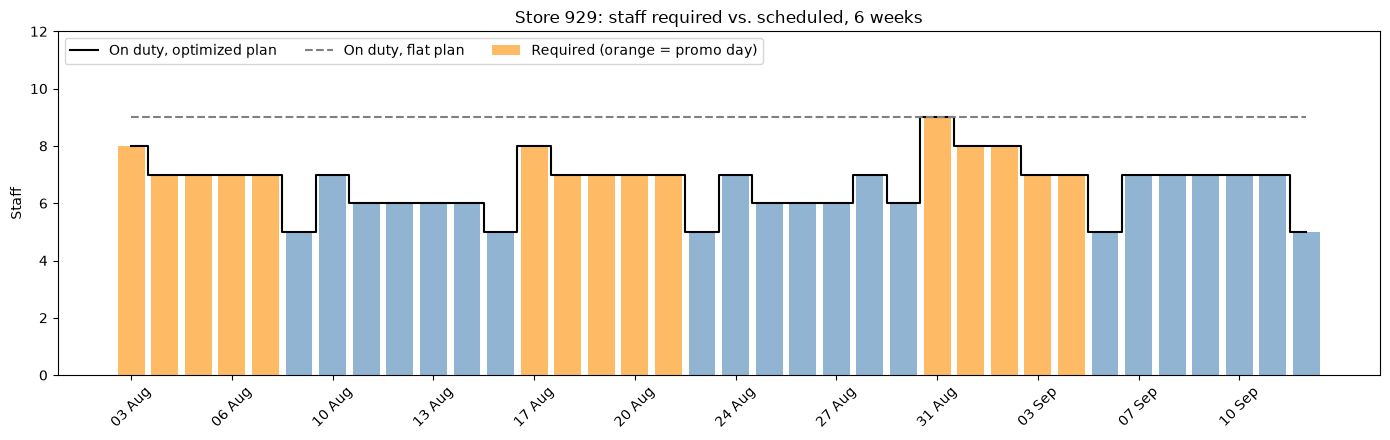

In [5]:
promo = rows["Promo"].to_numpy().reshape(6, 6).ravel()
labels = [f"{d:%d %b}" for d in rows["Date"]]
x = np.arange(36)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(x, required.ravel(), color=np.where(promo == 1, "darkorange", "steelblue"), alpha=0.6,
       label="Required (orange = promo day)")
ax.step(x, plan["on_duty"].ravel(), where="mid", color="black", label="On duty, optimized plan")
ax.step(x, flat["on_duty"].ravel(), where="mid", color="gray", linestyle="--", label="On duty, flat plan")
ax.set_xticks(x[::3], labels[::3], rotation=45)
ax.set_ylabel("Staff")
ax.set_title(f"Store {FEATURED}: staff required vs. scheduled, 6 weeks")
ax.set_ylim(0, required.max() + 3)
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.savefig(IMAGES / "staffing_plan.png", dpi=150, bbox_inches="tight")
plt.show()

### Why not just plan for an average day?
A planner without a forecast might staff every day at the average requirement. That is cheaper than
staffing for the peak, but it leaves promotion days short.

In [6]:
open_days = required > 0
average_level = int(np.ceil(required[open_days].mean()))
short = open_days & (required > average_level)
promo_grid = rows["Promo"].to_numpy().reshape(6, 6)
print(f"Average plan: {average_level} staff every open day")
print(f"Days short-staffed: {int(short.sum())} of {int(open_days.sum())} open days "
      f"({int((required - average_level)[short].sum())} staff-shifts missing)")
print(f"Of those, promotion days: {int((short & (promo_grid == 1)).sum())}")
print(f"Promotion days overall: {int((open_days & (promo_grid == 1)).sum())} of {int(open_days.sum())}")

Average plan: 7 staff every open day
Days short-staffed: 5 of 36 open days (6 staff-shifts missing)
Of those, promotion days: 5
Promotion days overall: 15 of 36


### Finding: featured store
Store 929 needs 5 to 9 staff a day, peaking on promotion Mondays. The optimized plan costs **30,960 EUR for
6 weeks** (46 full-time weeks plus 10 part-time shifts) vs. **42,048 EUR** for staffing every day at the
9-person peak: **26.4% less**, with every day covered and no idle staff (on duty equals required every day).
Part-time shifts appear only where full-timers can't fit the shape of the week, mostly around promotion
peaks. Planning to an average day instead (7 staff) would leave 5 days short-staffed, and all 5 are
promotion days. That is why a promotion-aware forecast matters for staffing.

### Every store
The same optimization for each store that closes on Sundays.

In [7]:
results = []
for store in eligible:
    _, store_customers, store_open = store_grids(store)
    need = required_staff(store_customers, store_open, DEFAULTS["customers_per_staff"],
                          DEFAULTS["safety_buffer"], DEFAULTS["min_staff"])
    best = solve_plan(need, DEFAULTS["full_time_weekly_cost"], DEFAULTS["part_time_shift_cost"])
    baseline = solve_plan(flat_requirement(need), DEFAULTS["full_time_weekly_cost"], DEFAULTS["part_time_shift_cost"])
    results.append({
        "Store": int(store),
        "avg_forecast_customers": round(float(store_customers[store_open == 1].mean()), 0),
        "optimized_cost": best["cost"],
        "flat_cost": baseline["cost"],
        "full_time_weeks": int(best["full_time"].sum()),
        "part_time_shifts": int(best["part_time"].sum()),
    })

all_stores = pd.DataFrame(results)
all_stores["savings"] = all_stores["flat_cost"] - all_stores["optimized_cost"]
all_stores["savings_pct"] = all_stores["savings"] / all_stores["flat_cost"]
all_stores.to_csv(APP_DATA / "staffing_all_stores.csv", index=False)

print(f"{len(all_stores)} stores planned")
print(f"Total 6-week labor cost: optimized {all_stores['optimized_cost'].sum() / 1e6:.2f}M EUR vs. "
      f"flat {all_stores['flat_cost'].sum() / 1e6:.2f}M EUR")
print(f"Savings: {all_stores['savings'].sum() / 1e6:.2f}M EUR "
      f"({all_stores['savings'].sum() / all_stores['flat_cost'].sum():.1%}) over 6 weeks")
all_stores["savings_pct"].describe(percentiles=[0.1, 0.5, 0.9]).round(3)

829 stores planned
Total 6-week labor cost: optimized 25.97M EUR vs. flat 34.23M EUR
Savings: 8.26M EUR (24.1%) over 6 weeks


count    829.000
mean       0.239
std        0.063
min        0.000
10%        0.156
50%        0.241
90%        0.318
max        0.425
Name: savings_pct, dtype: float64

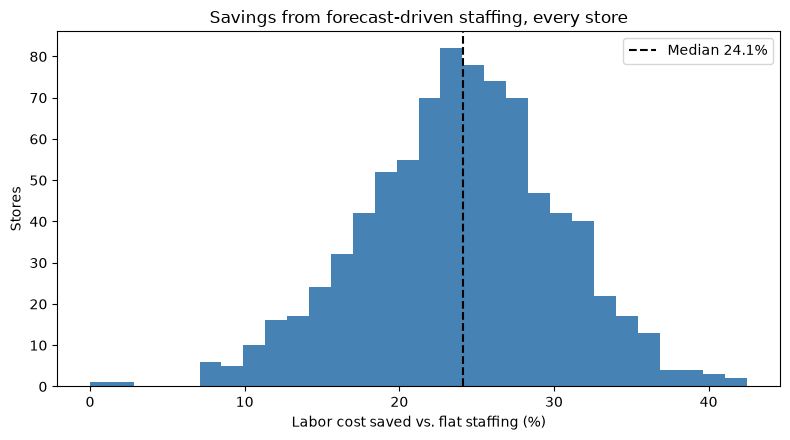

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(all_stores["savings_pct"] * 100, bins=30, color="steelblue")
ax.axvline(all_stores["savings_pct"].median() * 100, color="black", linestyle="--",
           label=f"Median {all_stores['savings_pct'].median():.1%}")
ax.set_xlabel("Labor cost saved vs. flat staffing (%)")
ax.set_ylabel("Stores")
ax.set_title("Savings from forecast-driven staffing, every store")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "savings_all_stores.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: all stores
Across all 829 stores that close on Sundays, the optimized plans cost **25.97M EUR vs. 34.23M EUR** for flat
staffing over the same 6 weeks: **8.26M EUR saved (24.1%)**. The median store saves 24.1%, and 80% of stores
save between 15.6% and 31.8%. Stores with sharper weekly peaks save the most; a store whose requirement is
the same every day has nothing to gain.

### The Excel Solver version
`excel/staffing_plan.xlsx` holds the same model for the featured store, built with live formulas so a
planner can change the assumptions (yellow and blue cells) and re-solve with **Data > Solver**. The next
cell builds the workbook; the one after opens it in Excel and runs Solver to prove it reaches the same
optimum.

In [9]:
from openpyxl import Workbook
from openpyxl.formatting.rule import CellIsRule
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter

BOLD = Font(bold=True)
TITLE = Font(bold=True, size=14)
INPUT = PatternFill("solid", fgColor="DDEBF7")
DECISION = PatternFill("solid", fgColor="FFF2CC")
RESULT = PatternFill("solid", fgColor="E2EFDA")
THIN = Side(style="thin", color="BFBFBF")
BOX = Border(left=THIN, right=THIN, top=THIN, bottom=THIN)
COLS = [get_column_letter(c) for c in range(2, 8)]  # B..G = Mon..Sat


def grid(ws, top, title, header, values=None, fill=None, number_format="0", formula=None):
    """Writes a 6x6 week-by-day block. Returns the range of its 36 value cells."""
    ws.cell(top, 1, title).font = BOLD
    for j, label in enumerate(header):
        cell = ws.cell(top + 1, 2 + j, label)
        cell.font = BOLD
        cell.alignment = Alignment(horizontal="center")
    for i in range(6):
        ws.cell(top + 2 + i, 1, weeks[i])
        for j in range(6):
            cell = ws.cell(top + 2 + i, 2 + j)
            cell.value = formula(top + 2 + i, COLS[j]) if formula else values[i][j]
            cell.number_format = number_format
            cell.border = BOX
            cell.alignment = Alignment(horizontal="center")
            if fill:
                cell.fill = fill
    return f"$B${top + 2}:$G${top + 7}"


wb = Workbook()
ws = wb.active
ws.title = "Staffing Plan"
ws["A1"] = f"Store {FEATURED}: 6-week staffing plan (Mon {START:%d %b} to Sat {END:%d %b %Y})"
ws["A1"].font = TITLE
ws["A2"] = "Blue = assumptions you can change. Yellow = Solver decides. Green = result. Data > Solver > Solve to re-optimize."

ws["A4"] = "Assumptions"
ws["A4"].font = BOLD
assumptions = [
    ("Customers one employee serves per 8-hour shift", DEFAULTS["customers_per_staff"], "0"),
    ("Safety buffer for forecast error", DEFAULTS["safety_buffer"], "0%"),
    ("Minimum staff on duty when open", DEFAULTS["min_staff"], "0"),
    ("Full-time employee, cost per week (5 shifts)", DEFAULTS["full_time_weekly_cost"], '#,##0 "EUR"'),
    ("Part-time shift cost", DEFAULTS["part_time_shift_cost"], '#,##0 "EUR"'),
]
for i, (label, value, fmt) in enumerate(assumptions):
    ws.cell(5 + i, 1, label)
    cell = ws.cell(5 + i, 3, value)
    cell.fill, cell.number_format, cell.border = INPUT, fmt, BOX

customers_range = grid(ws, 11, "Forecast customers (from the LightGBM model)", DAYS, values=np.round(customers).astype(int))
open_range = grid(ws, 20, "Store open (1 = yes)", DAYS, values=is_open)
required_range = grid(
    ws, 29, "Staff required", DAYS,
    formula=lambda r, c: f"=IF({c}{r - 9}=1,MAX($C$7,ROUNDUP({c}{r - 18}*(1+$C$6)/$C$5,0)),0)",
)
full_time_range = grid(ws, 38, "DECISION: full-time employees by day off", [f"Off {d}" for d in DAYS],
                       values=plan["full_time"], fill=DECISION)
part_time_range = grid(ws, 47, "DECISION: part-time shifts", DAYS, values=plan["part_time"], fill=DECISION)
on_duty_range = grid(
    ws, 56, "Staff on duty", DAYS,
    formula=lambda r, c: f"=SUM($B{r - 18}:$G{r - 18})-{c}{r - 18}+{c}{r - 9}",
)
spare_range = grid(ws, 65, "Spare staff (on duty minus required)", DAYS,
                   formula=lambda r, c: f"={c}{r - 9}-{c}{r - 36}")
ws.conditional_formatting.add(spare_range.replace("$", ""),
                              CellIsRule(operator="lessThan", formula=["0"], fill=PatternFill("solid", fgColor="F8CBAD")))

ws["A74"] = "Cost (6 weeks)"
ws["A74"].font = BOLD
costs = [
    ("Full-time cost", f"=SUM({full_time_range})*$C$8"),
    ("Part-time cost", f"=SUM({part_time_range})*$C$9"),
    ("TOTAL LABOR COST (Solver minimizes this)", "=C75+C76"),
    (None, None),
    ("Flat plan: staff every open day for the busiest day", flat["cost"]),
    ("Saved by the optimized plan", "=1-C77/C79"),
]
for i, (label, value) in enumerate(costs):
    if label is None:
        continue
    ws.cell(75 + i, 1, label)
    cell = ws.cell(75 + i, 3, value)
    cell.number_format = "0.0%" if "Saved" in label else '#,##0 "EUR"'
    cell.border = BOX
    if "TOTAL" in label or "Saved" in label:
        cell.fill, cell.font = RESULT, BOLD
        ws.cell(75 + i, 1).font = BOLD

ws.column_dimensions["A"].width = 50
for c in COLS:
    ws.column_dimensions[c].width = 10
ws.column_dimensions["C"].width = 12
ws.freeze_panes = "B4"

detail = wb.create_sheet("Forecast Detail")
detail.append(["Date", "Weekday", "Open", "Promo", "State holiday", "Forecast sales (EUR)", "Forecast customers"])
for cell in detail[1]:
    cell.font = BOLD
for r in rows.itertuples():
    detail.append([r.Date.to_pydatetime(), DAYS[r.DayOfWeek - 1], r.Open, r.Promo, r.StateHoliday,
                   round(r.forecast_sales), round(r.forecast_customers)])
for row in detail.iter_rows(min_row=2, max_col=1):
    row[0].number_format = "ddd dd mmm yyyy"
for col, width in zip("ABCDEFG", [16, 10, 7, 7, 13, 20, 19]):
    detail.column_dimensions[col].width = width

guide = wb.create_sheet("How It Works")
lines = [
    "How this model works",
    "",
    "Goal: schedule enough staff for forecast customer traffic at the lowest wage cost.",
    "Staff required = forecast customers x (1 + safety buffer) / customers per employee, rounded up, minimum crew when open.",
    "Full-time employees work 5 of the 6 days (Mon-Sat), with one day off per week. Each yellow cell in the full-time",
    "block is how many full-timers take that day off that week, so on-duty full-timers = week total minus that day's cell.",
    "Part-time shifts can be booked for any single day but cost more per hour than full-time.",
    "",
    "Solver setup (already saved in this workbook: Data > Solver > Solve):",
    "  Set objective: $C$77 (total labor cost), To: Min",
    f"  By changing: {full_time_range}, {part_time_range}",
    f"  Subject to: {on_duty_range} >= {required_range}   (every day covered)",
    f"              {full_time_range} = integer, {part_time_range} = integer",
    "  Make unconstrained variables non-negative: on",
    "  Solving method: Simplex LP",
    "",
    "If Data > Solver is missing: File > Options > Add-ins > Manage Excel Add-ins > Go > tick Solver Add-in.",
    "Try it: raise the safety buffer to 20% or the part-time cost to 170, then solve again.",
]
for line in lines:
    guide.append([line])
guide["A1"].font = TITLE
guide.column_dimensions["A"].width = 120

workbook_path = EXCEL / "staffing_plan.xlsx"
wb.save(workbook_path)
print("Saved", workbook_path.relative_to(ROOT))
print("Objective cell C77, decisions", full_time_range, part_time_range, "constraint", on_duty_range, ">=", required_range)

Saved excel\staffing_plan.xlsx
Objective cell C77, decisions $B$40:$G$45 $B$49:$G$54 constraint $B$58:$G$63 >= $B$31:$G$36


In [10]:
import subprocess

script = r"""
$ErrorActionPreference = 'Stop'
$xl = New-Object -ComObject Excel.Application
$xl.Visible = $false
$xl.DisplayAlerts = $false
try {
    foreach ($addin in $xl.AddIns) { if ($addin.Name -like 'SOLVER*') { $addin.Installed = $false; $addin.Installed = $true } }
    $wb = $xl.Workbooks.Open('WORKBOOK')
    $ws = $wb.Worksheets.Item('Staffing Plan')
    $ws.Activate()
    $ws.Range('FULLTIME').Value2 = 0
    $ws.Range('PARTTIME').Value2 = 0
    $xl.Calculate()
    $xl.Run('Solver.xlam!SolverReset')
    $xl.Run('Solver.xlam!SolverOk', '$C$77', 2, 0, 'FULLTIME,PARTTIME', 2) | Out-Null
    $xl.Run('Solver.xlam!SolverAdd', 'ONDUTY', 3, 'REQUIRED') | Out-Null
    $xl.Run('Solver.xlam!SolverAdd', 'FULLTIME', 4, 'integer') | Out-Null
    $xl.Run('Solver.xlam!SolverAdd', 'PARTTIME', 4, 'integer') | Out-Null
    $m = [System.Reflection.Missing]::Value
    $xl.Run('Solver.xlam!SolverOptions', $m, $m, $m, $m, $m, $m, $m, $m, 0) | Out-Null
    $code = $xl.Run('Solver.xlam!SolverSolve', $true)
    $xl.Run('Solver.xlam!SolverFinish', 1) | Out-Null
    $xl.Calculate()
    "solver_result=$code"
    "objective=" + $ws.Range('C77').Value2
    $wb.Save()
    $wb.Close($false)
} finally {
    $xl.Quit()
    [System.Runtime.InteropServices.Marshal]::ReleaseComObject($xl) | Out-Null
}
"""
for key, value in {"WORKBOOK": str(workbook_path), "FULLTIME": full_time_range, "PARTTIME": part_time_range,
                   "ONDUTY": on_duty_range, "REQUIRED": required_range}.items():
    script = script.replace(key, value)

try:
    out = subprocess.run(["powershell", "-NoProfile", "-Command", script], capture_output=True, text=True, timeout=300)
    report = dict(line.split("=", 1) for line in out.stdout.split() if "=" in line)
    excel_cost = float(report["objective"])
    print(f"Excel Solver result code {report['solver_result']} (0 = optimal solution found)")
    print(f"Excel Solver cost: {excel_cost:,.0f} EUR | Python (scipy) cost: {plan['cost']:,.0f} EUR")
    print("Same optimum:", abs(excel_cost - plan["cost"]) < 0.5)
except Exception as error:
    print("Could not run Excel Solver automatically here (needs Windows + Excel):", error, out.stderr[-500:] if "out" in dir() else "")

Excel Solver result code 0 (0 = optimal solution found)
Excel Solver cost: 30,960 EUR | Python (scipy) cost: 30,960 EUR
Same optimum: True


### Summary
- **Forecast to decision:** forecast customers become daily staff requirements (with a 10% safety buffer,
  above the forecast's 6.8% typical error), and an integer program finds the cheapest mix of full-time
  day-off patterns and part-time shifts that covers every day.
- **Store 929:** 30,960 EUR vs. 42,048 EUR, 26.4% saved over 6 weeks. **All 829 stores:** 8.26M EUR saved (24.1%).
- **Excel Solver gives the same answer.** `excel/staffing_plan.xlsx` has the model with live formulas. Run
  from an empty plan, Excel Solver (Simplex LP, integer) found exactly the same 30,960 EUR optimum as Python,
  and the Solver setup is saved in the workbook: open it and press Data > Solver > Solve.
- **Assumptions to tune** (blue cells in the workbook): customers per employee per shift, safety buffer,
  minimum crew, and the two wage costs. They are illustrative, not Rossmann's real figures.